In [1]:
import pandas as pd
from pandas import DataFrame  as df

#데이터 불러오기 시간이랑 트윗 텍스트만
Data = pd.read_csv("청년층과 노년층 모두 많이 대출한 책(csv).csv")

Data

,검색어,저자,책소개
0,불편한 편의점,김호연,“근데 이게 마지막 술이에요. 이거 먹고 술 끊는 조건으로 우리 가게 일 좀 봐줘요...
1,물고기는 존재하지 않는다,룰루 밀러,‘혼돈’만이 우리의 유일한 지배자라고 아버지는 내게 알려주었다. 혼돈이라는 막무가내...
2,아버지의 해방일지,정지아,아버지가 죽었다. 전봇대에 머리를 박고. 평생을 정색하고 살아온 아버지가 전봇대에 ...
3,홍학의 자리,정해연,“이 행복이 영원할 거라고 생각한 적은 없었다.\n그러나 이런 끝을 상상한 적도 없...
4,밝은 밤,최은영,왜 개새끼라고 하나. 개가 사람한테 너무 잘해줘서 그런 거 아닌가. 아무 조건도 없...
5,지구 끝의 온실,김초엽,아영은 그렇게 느리고 꾸물거리는 것들이 멀리 퍼져 나가는 과정을 지켜보는 것이 좋았...
6,달러구트 꿈 백화점,이미예,“저는 세 번째 제자의 선택이 잘 이해되지 않았어요. 첫 번째 제자가 다스리기로 한...
7,도둑맞은 집중력,요한 하리,그는 집중력 문제의 증가를 비만율의 증가에 비유하는 방식이 이해에 도움이 될 수 있...
8,아주 희미한 빛으로도,최은영,"나의 결핍을 안고서 그것을 너무 미워하지도, 너무 가여워하지도 않고 그저 하루하루를..."
9,세이노의 가르침,세이노(SayNo),삶이 그대를 속이면 분노하라.\n---「첫 문장」중에서\n\n인생은 자전거와 같다....


In [2]:
Data.책소개 = Data.책소개.astype(str)

In [3]:
import pandas as pd
import numpy as np

# 데이터 프레임의 'text' 열의 값들을 str 형식으로 바꾸기
Data['책소개'] = Data['책소개'].astype(str)

# 한글이 아니면 빈 문자열로 바꾸기
Data['책소개'] = Data['책소개'].str.replace('[^ㄱ-ㅎㅏ-ㅣ가-힣]', ' ', regex=True)

# 빈 문자열을 NAN 값으로 바꾸기
Data['책소개'] = Data['책소개'].replace({'': np.nan})
Data['책소개'] = Data['책소개'].replace(r'^\s*$', np.nan, regex=True)

# NAN이 있는 행은 삭제
Data.dropna(subset=['책소개'], how='any', inplace=True)

# 인덱스 차곡차곡
Data = Data.reset_index(drop=True)

# 데이터 프레임에 null 값이 있는지 확인
print(Data.isnull().values.any())


False


In [4]:
from konlpy.tag import Okt
import pandas as pd
import numpy as np

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.extend([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

# 결과를 데이터프레임으로 변환
nouns_df = pd.DataFrame(data_word, columns=['명사'])

# 데이터프레임 출력
print(nouns_df)

       명사
0      부자
1      실존
2     스스로
3      서구
4     평상시
...   ...
1859  판가름
1860   저번
1861   이모
1862   정해
1863  이제야

[1864 rows x 1 columns]


In [5]:
from konlpy.tag import Okt
import pandas as pd
import numpy as np
import gensim
import re
from gensim.corpora import Dictionary

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.extend([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

# 결과를 데이터프레임으로 변환
nouns_df = pd.DataFrame(data_word, columns=['명사'])

# 데이터프레임 출력
print(nouns_df)

# LDA 모델 생성
# 명사 리스트를 문서 형태로 변환
documents = [data_word]  # 각 문서에 대해 명사 리스트를 사용

# 사전 생성
id2word = Dictionary(documents)

# 코퍼스 생성
corpus = [id2word.doc2bow(doc) for doc in documents]

# LDA 모델 설정
num_topics = 10  # 토픽 개수 설정
lda_model = gensim.models.LdaModel(corpus, num_topics=num_topics, id2word=id2word, passes=25, random_state=42)

# 결과를 데이터프레임으로 변환
topics = []
for idx, topic in lda_model.print_topics(-1):
    # 주요 단어를 쉼표로 구분하여 저장
    topic_words = topic.split(" + ")
    topic_words = [word.split("*")[1].strip().replace('"', '') for word in topic_words]
    topics.append((idx, ", ".join(topic_words)))

# 데이터프레임 생성
topics_df = pd.DataFrame(topics, columns=['토픽 번호', '주요 단어'])

# 데이터프레임 출력 
print(topics_df)

       명사
0      부자
1      실존
2     스스로
3      서구
4     평상시
...   ...
1859  판가름
1860   저번
1861   이모
1862   정해
1863  이제야

[1864 rows x 1 columns]
   토픽 번호                                         주요 단어
0      0  소리, 공식, 카디건, 성도, 아랑곳, 고상욱, 엄마, 비야, 슬로모션, 대다수
1      1      고통, 거품, 직접, 금기, 작품, 푸른, 시상식, 명숙, 신호등, 식량
2      2      과거, 덕분, 꿈속, 무방비, 종족, 일부, 부부, 시스템, 오른, 비록
3      3    허리춤, 수영, 한바탕, 기계, 외람, 지장, 샹들리에, 포함, 비롯, 환각
4      4     절대, 언니, 느릿느릿, 다희, 염치, 웃음, 계층, 수량, 최적화, 인위
5      5       문득, 이유, 모습, 조지, 무엇, 거부, 클루지, 햇빛, 종류, 가치
6      6  정색, 결심, 행색, 모순, 식이요법, 일반, 복숭아, 대우, 영정사진, 방법론
7      7   평상시, 전역, 일명, 증식, 자격, 휴머노이드, 약초, 실마리, 번역, 중인
8      8      종이, 앞치마, 일종, 독자, 아이, 제발, 도시락, 달걀, 공경, 사이
9      9       상품, 시야, 대란, 망각, 악수, 자식, 주인공, 욕심, 피하, 양감


In [6]:
font = 'DoHyeon-Regular.ttf'

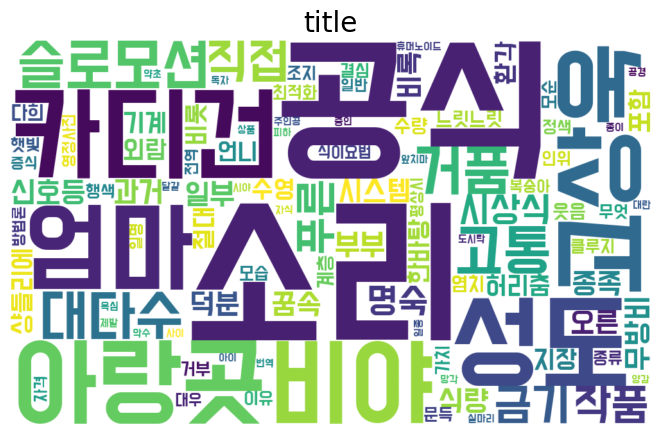

In [7]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 주요 단어를 문자열로 변환 (예: '단어1, 단어2, 단어3')
word_string = ", ".join(topics_df['주요 단어'].tolist())

# 워드클라우드 생성
wordcloud = WordCloud(
    font_path= font,  # 한글 폰트 경로
    width=1000,
    height=600,
    background_color='white',
    colormap='viridis',  # 색상 맵 설정
    max_words=200,  # 최대 단어 수
    random_state=42  # 랜덤 상태 설정
).generate(word_string)

# 워드클라우드 시각화
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # 축 제거
plt.title('title', fontsize=20)
plt.show()